# 03 - Preprocessing & ML Baseline (Shot Made Prediction)

**Tujuan notebook ini:**

1. Bangun tabel final untuk modeling dari hasil join `nbastats` (event, difilter `EVENTMSGTYPE IN (1,2)`)
   + `shotdetail` (hasil tembakan) via composite key `(GAME_ID, EVENTNUM = GAME_EVENT_ID)`, memakai
   keputusan desain yang sama seperti notebook 02 (termasuk forward-fill `SCOREMARGIN`).
2. Latih baseline **Logistic Regression** (Spark MLlib) untuk memprediksi `SHOT_MADE_FLAG` dari fitur
   shot: jarak, zona, tipe shot, periode, sisa waktu, margin skor, dan musim.
3. Bandingkan 2 skema split: random 80/20 vs temporal holdout (train musim <=2014, test musim >=2015)
   untuk melihat indikasi *concept drift* akibat perubahan gaya main (makin banyak 3PT antar musim).
4. Interpretasi sederhana lewat koefisien model.

Notebook ini independen (tidak mengandalkan state notebook 02 yang sudah berhenti) - join dan
forward-fill margin dibangun ulang dari Parquet notebook 01.

## Setup: SparkSession & path

In [1]:
import os
import sys
import json

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.environ.setdefault("JAVA_HOME", r"C:\Program Files\Java\jre-1.8")
os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
# Driver memory must be set before the JVM gateway launches (see notebook 01 for why).
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 6g pyspark-shell"

PARQUET_DIR = os.path.join(PROJECT_ROOT, "output", "parquet")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "output")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
os.makedirs(REPORTS_DIR, exist_ok=True)

In [2]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (
    SparkSession.builder.appName("NBA-Preprocessing-ML-Baseline")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

## 1. Load & rebuild hasil join notebook 02

Load Parquet `nbastats`/`shotdetail`, drop kolom yang null rate-nya sangat tinggi dan tidak relevan
untuk modeling (`NEUTRALDESCRIPTION`, `PLAYER3_*` - null ini valid by design di tabel event mentah,
tapi tidak berguna sebagai fitur), lalu bangun ulang join + forward-fill `SCOREMARGIN` seperti di
notebook 02.

In [3]:
nbastats_raw = spark.read.parquet(os.path.join(PARQUET_DIR, "nbastats"))
shotdetail_raw = spark.read.parquet(os.path.join(PARQUET_DIR, "shotdetail"))

drop_cols_nbastats = [
    "NEUTRALDESCRIPTION",
    "PLAYER3_NAME",
    "PLAYER3_TEAM_ID",
    "PLAYER3_TEAM_CITY",
    "PLAYER3_TEAM_NICKNAME",
    "PLAYER3_TEAM_ABBREVIATION",
]
nbastats = nbastats_raw.drop(*drop_cols_nbastats)
shotdetail = shotdetail_raw

print("nbastats columns after drop:", nbastats.columns)
print("nbastats rows:", nbastats.count(), "| shotdetail rows:", shotdetail.count())

nbastats columns after drop: ['GAME_ID', 'EVENTNUM', 'EVENTMSGTYPE', 'EVENTMSGACTIONTYPE', 'PERIOD', 'WCTIMESTRING', 'PCTIMESTRING', 'HOMEDESCRIPTION', 'VISITORDESCRIPTION', 'SCORE', 'SCOREMARGIN', 'PERSON1TYPE', 'PLAYER1_ID', 'PLAYER1_NAME', 'PLAYER1_TEAM_ID', 'PLAYER1_TEAM_CITY', 'PLAYER1_TEAM_NICKNAME', 'PLAYER1_TEAM_ABBREVIATION', 'PERSON2TYPE', 'PLAYER2_ID', 'PLAYER2_NAME', 'PLAYER2_TEAM_ID', 'PLAYER2_TEAM_CITY', 'PLAYER2_TEAM_NICKNAME', 'PLAYER2_TEAM_ABBREVIATION', 'PERSON3TYPE', 'PLAYER3_ID', 'VIDEO_AVAILABLE_FLAG', 'game_type', 'season']
nbastats rows: 16699012 | shotdetail rows: 6094438


### 1.1 Dedup: buang 707 duplicate key-groups yang ditemukan di notebook 02

Dedup `nbastats` by `(GAME_ID, EVENTNUM)` keep first (baris-baris yang sama key-nya identik secara
data, urutan "first" dipilih deterministik lewat `row_number()` supaya hasilnya reproducible).

In [4]:
from pyspark.sql.functions import row_number

dedup_window_nb = Window.partitionBy("GAME_ID", "EVENTNUM").orderBy(F.monotonically_increasing_id())
nbastats_fg_all = (
    nbastats.filter(F.col("EVENTMSGTYPE").isin(1, 2))
    .withColumn("_rn", row_number().over(dedup_window_nb))
    .filter(F.col("_rn") == 1)
    .drop("_rn")
)

dedup_window_sd = Window.partitionBy("GAME_ID", "GAME_EVENT_ID").orderBy(F.monotonically_increasing_id())
shotdetail_dedup = (
    shotdetail.withColumn("_rn", row_number().over(dedup_window_sd))
    .filter(F.col("_rn") == 1)
    .drop("_rn")
)

print("nbastats FG events after dedup:", nbastats_fg_all.count())
print("shotdetail after dedup:", shotdetail_dedup.count())

nbastats FG events after dedup: 6094492
shotdetail after dedup: 6094438


### 1.2 Forward-fill `SCOREMARGIN` (sama seperti notebook 02)

`SCOREMARGIN` hanya terisi pada baris yang mengubah skor; forward-fill memakai window function supaya
setiap event (termasuk shot yang meleset) tetap punya estimasi margin skor terkini.

In [5]:
margin_numeric = F.when(F.col("SCOREMARGIN") == "TIE", F.lit(0)).otherwise(
    F.regexp_replace(F.col("SCOREMARGIN"), "[^0-9-]", "").cast("int")
)

ffill_window = Window.partitionBy("GAME_ID").orderBy("EVENTNUM").rowsBetween(Window.unboundedPreceding, 0)

nbastats_fg = nbastats_fg_all.withColumn("margin_numeric", margin_numeric).withColumn(
    "margin_ffill", F.last("margin_numeric", ignorenulls=True).over(ffill_window)
)

### 1.3 Join: INNER join otomatis membuang orphan rows

`INNER` join pada `(GAME_ID, EVENTNUM = GAME_EVENT_ID)` secara alami membuang baris yang GAME_ID+event
id-nya tidak match di kedua sisi (orphan rows dari notebook 02, ~0.01% dari masing-masing tabel) -
tidak perlu langkah pembuangan terpisah.

In [6]:
joined_df = nbastats_fg.alias("n").join(
    shotdetail_dedup.alias("s"),
    (F.col("n.GAME_ID") == F.col("s.GAME_ID")) & (F.col("n.EVENTNUM") == F.col("s.GAME_EVENT_ID")),
    "inner",
).select(
    F.col("n.GAME_ID").alias("GAME_ID"),
    F.col("n.EVENTNUM").alias("EVENTNUM"),
    F.col("n.PERIOD").alias("PERIOD"),
    F.col("n.margin_ffill").alias("SCOREMARGIN"),
    F.col("s.season").alias("SEASON"),
    F.col("s.SHOT_DISTANCE").alias("SHOT_DISTANCE"),
    F.col("s.SHOT_ZONE_BASIC").alias("SHOT_ZONE_BASIC"),
    F.col("s.SHOT_ZONE_AREA").alias("SHOT_ZONE_AREA"),
    F.col("s.SHOT_TYPE").alias("SHOT_TYPE"),
    F.col("s.MINUTES_REMAINING").alias("MINUTES_REMAINING"),
    F.col("s.SECONDS_REMAINING").alias("SECONDS_REMAINING"),
    F.col("s.SHOT_MADE_FLAG").alias("SHOT_MADE_FLAG"),
)

print("joined_df row count (post dedup, inner-join, orphans excluded):", joined_df.count())

joined_df row count (post dedup, inner-join, orphans excluded): 6093766


## 2. Preprocessing: tabel final untuk modeling

- Hitung `time_remaining_seconds = MINUTES_REMAINING*60 + SECONDS_REMAINING`.
- Pilih hanya kolom fitur yang akan dipakai model: `SHOT_DISTANCE`, `SHOT_ZONE_BASIC`,
  `SHOT_ZONE_AREA`, `SHOT_TYPE`, `PERIOD`, `time_remaining_seconds`, `SCOREMARGIN`, `SEASON`,
  `SHOT_MADE_FLAG` (label).
- `dropna` di kolom-kolom itu supaya tidak ada null tersisa di tabel modeling.

In [7]:
feature_cols_final = [
    "SHOT_DISTANCE",
    "SHOT_ZONE_BASIC",
    "SHOT_ZONE_AREA",
    "SHOT_TYPE",
    "PERIOD",
    "time_remaining_seconds",
    "SCOREMARGIN",
    "SEASON",
    "SHOT_MADE_FLAG",
]

modeling_table = (
    joined_df.withColumn(
        "time_remaining_seconds", F.col("MINUTES_REMAINING") * 60 + F.col("SECONDS_REMAINING")
    )
    .select(*feature_cols_final)
    .dropna(subset=feature_cols_final)
)

remaining_nulls = modeling_table.select(
    [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in feature_cols_final]
).collect()[0].asDict()
print("Null count per feature column after dropna (should all be 0):", remaining_nulls)

modeling_table.cache()
final_row_count = modeling_table.count()
print("Final modeling table row count:", final_row_count)

Null count per feature column after dropna (should all be 0): {'SHOT_DISTANCE': 0, 'SHOT_ZONE_BASIC': 0, 'SHOT_ZONE_AREA': 0, 'SHOT_TYPE': 0, 'PERIOD': 0, 'time_remaining_seconds': 0, 'SCOREMARGIN': 0, 'SEASON': 0, 'SHOT_MADE_FLAG': 0}
Final modeling table row count: 6049202


### Class balance `SHOT_MADE_FLAG`

In [8]:
class_balance = (
    modeling_table.groupBy("SHOT_MADE_FLAG")
    .count()
    .withColumn("pct", F.round(F.col("count") / final_row_count * 100, 2))
    .orderBy("SHOT_MADE_FLAG")
)
class_balance.show()

class_balance_rows = class_balance.collect()
class_balance_summary = {
    "final_row_count": final_row_count,
    "class_counts": {str(r["SHOT_MADE_FLAG"]): {"count": r["count"], "pct": r["pct"]} for r in class_balance_rows},
}
with open(os.path.join(OUTPUT_DIR, "ml_class_balance.json"), "w", encoding="utf-8") as f:
    json.dump(class_balance_summary, f, indent=2)
print("Saved -> output/ml_class_balance.json")

+--------------+-------+-----+
|SHOT_MADE_FLAG|  count|  pct|
+--------------+-------+-----+
|             0|3276707|54.17|
|             1|2772495|45.83|
+--------------+-------+-----+

Saved -> output/ml_class_balance.json


### Simpan tabel modeling final sebagai Parquet

In [9]:
modeling_table_path = os.path.join(PARQUET_DIR, "modeling_table")
modeling_table.write.mode("overwrite").parquet(modeling_table_path)
print("Saved -> output/parquet/modeling_table/")

Saved -> output/parquet/modeling_table/


## 3. ML baseline (Spark MLlib)

Pipeline: `StringIndexer` + `OneHotEncoder` untuk 3 fitur kategorikal (`SHOT_ZONE_BASIC`,
`SHOT_ZONE_AREA`, `SHOT_TYPE`) -> `VectorAssembler` -> `LogisticRegression`.

**Keputusan desain:** `SEASON` diperlakukan sebagai fitur **numerik** (bukan one-hot), karena musim
punya urutan alami (lebih masuk akal sebagai tren waktu daripada 29 kategori lepas), dan supaya evaluasi
temporal holdout di bawah tetap bermakna (model bisa belajar tren linear seiring musim, bukan
memory-kan kategori musim spesifik).

In [10]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

categorical_cols = ["SHOT_ZONE_BASIC", "SHOT_ZONE_AREA", "SHOT_TYPE"]
numeric_cols = ["SHOT_DISTANCE", "PERIOD", "time_remaining_seconds", "SCOREMARGIN", "SEASON"]

ml_table = modeling_table
for c in numeric_cols:
    ml_table = ml_table.withColumn(c, F.col(c).cast("double"))
ml_table = ml_table.withColumn("label", F.col("SHOT_MADE_FLAG").cast("double")).cache()

indexed_cols = [c + "_idx" for c in categorical_cols]
ohe_cols = [c + "_ohe" for c in categorical_cols]

indexers = [
    StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in categorical_cols
]
encoder = OneHotEncoder(inputCols=indexed_cols, outputCols=ohe_cols)
assembler = VectorAssembler(inputCols=ohe_cols + numeric_cols, outputCol="features")
lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=50)

pipeline = Pipeline(stages=indexers + [encoder, assembler, lr])

### Helper: latih, evaluasi, dan simpan hasil 1 skema split

In [11]:
import pandas as pd


def train_eval_split(train_df, test_df, split_name):
    model = pipeline.fit(train_df)
    predictions = model.transform(test_df).cache()

    auc = BinaryClassificationEvaluator(
        labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
    ).evaluate(predictions)
    accuracy = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="accuracy"
    ).evaluate(predictions)
    precision_made = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0
    ).evaluate(predictions)
    recall_made = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0
    ).evaluate(predictions)

    test_total = test_df.count()
    majority_count = test_df.groupBy("label").count().orderBy(F.desc("count")).first()["count"]
    naive_baseline_accuracy = majority_count / test_total

    confusion = (
        predictions.groupBy("label", "prediction")
        .count()
        .orderBy("label", "prediction")
        .toPandas()
    )

    metrics = {
        "split_name": split_name,
        "train_rows": train_df.count(),
        "test_rows": test_total,
        "accuracy": round(accuracy, 4),
        "auc_roc": round(auc, 4),
        "precision_made_class": round(precision_made, 4),
        "recall_made_class": round(recall_made, 4),
        "naive_majority_baseline_accuracy": round(naive_baseline_accuracy, 4),
    }
    print(f"=== {split_name} ===")
    print(json.dumps(metrics, indent=2))
    print("Confusion matrix (label=actual SHOT_MADE_FLAG, prediction=model output):")
    print(confusion)

    return model, metrics, confusion

### 3.1 Split 1 - Random 80/20

In [12]:
train_random, test_random = ml_table.randomSplit([0.8, 0.2], seed=42)

model_random, metrics_random, confusion_random = train_eval_split(train_random, test_random, "random_80_20")

with open(os.path.join(OUTPUT_DIR, "ml_random_split_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(metrics_random, f, indent=2)
confusion_random.to_csv(os.path.join(OUTPUT_DIR, "ml_random_split_confusion_matrix.csv"), index=False)
print("Saved -> output/ml_random_split_metrics.json, output/ml_random_split_confusion_matrix.csv")

=== random_80_20 ===
{
  "split_name": "random_80_20",
  "train_rows": 4840493,
  "test_rows": 1208709,
  "accuracy": 0.6134,
  "auc_roc": 0.6188,
  "precision_made_class": 0.6144,
  "recall_made_class": 0.4229,
  "naive_majority_baseline_accuracy": 0.5411
}
Confusion matrix (label=actual SHOT_MADE_FLAG, prediction=model output):
   label  prediction   count
0    0.0         0.0  506847
1    0.0         1.0  147218
2    1.0         0.0  320098
3    1.0         1.0  234546
Saved -> output/ml_random_split_metrics.json, output/ml_random_split_confusion_matrix.csv


### 3.2 Split 2 - Temporal holdout (train musim <= 2014, test musim >= 2015)

Tujuan: lihat apakah model yang dilatih di era sebelum 2015 (sebelum lonjakan besar 3PT attempt rate,
lihat notebook 02) masih akurat memprediksi shot di era sesudahnya - indikasi *concept drift* kalau
performanya jatuh dibanding split random.

In [13]:
train_temporal = ml_table.filter(F.col("SEASON") <= 2014)
test_temporal = ml_table.filter(F.col("SEASON") >= 2015)

model_temporal, metrics_temporal, confusion_temporal = train_eval_split(
    train_temporal, test_temporal, "temporal_holdout_le2014_vs_ge2015"
)

with open(os.path.join(OUTPUT_DIR, "ml_temporal_split_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(metrics_temporal, f, indent=2)
confusion_temporal.to_csv(os.path.join(OUTPUT_DIR, "ml_temporal_split_confusion_matrix.csv"), index=False)
print("Saved -> output/ml_temporal_split_metrics.json, output/ml_temporal_split_confusion_matrix.csv")

=== temporal_holdout_le2014_vs_ge2015 ===
{
  "split_name": "temporal_holdout_le2014_vs_ge2015",
  "train_rows": 3822805,
  "test_rows": 2226397,
  "accuracy": 0.6207,
  "auc_roc": 0.6302,
  "precision_made_class": 0.6415,
  "recall_made_class": 0.4221,
  "naive_majority_baseline_accuracy": 0.5338
}
Confusion matrix (label=actual SHOT_MADE_FLAG, prediction=model output):
   label  prediction   count
0    0.0         0.0  943778
1    0.0         1.0  244769
2    1.0         0.0  599795
3    1.0         1.0  438055
Saved -> output/ml_temporal_split_metrics.json, output/ml_temporal_split_confusion_matrix.csv


### 3.3 Perbandingan random vs temporal split

In [14]:
comparison = pd.DataFrame([metrics_random, metrics_temporal])[
    ["split_name", "train_rows", "test_rows", "accuracy", "auc_roc", "precision_made_class",
     "recall_made_class", "naive_majority_baseline_accuracy"]
]
print(comparison.to_string(index=False))
comparison.to_csv(os.path.join(OUTPUT_DIR, "ml_split_comparison.csv"), index=False)
print("\nSaved -> output/ml_split_comparison.csv")

acc_drop = metrics_random["accuracy"] - metrics_temporal["accuracy"]
auc_drop = metrics_random["auc_roc"] - metrics_temporal["auc_roc"]
print(f"\nAccuracy drop (random - temporal): {acc_drop:.4f}")
print(f"AUC-ROC drop (random - temporal): {auc_drop:.4f}")

                       split_name  train_rows  test_rows  accuracy  auc_roc  precision_made_class  recall_made_class  naive_majority_baseline_accuracy
                     random_80_20     4840493    1208709    0.6134   0.6188                0.6144             0.4229                            0.5411
temporal_holdout_le2014_vs_ge2015     3822805    2226397    0.6207   0.6302                0.6415             0.4221                            0.5338

Saved -> output/ml_split_comparison.csv

Accuracy drop (random - temporal): -0.0073
AUC-ROC drop (random - temporal): -0.0114


**Interpretasi:** kalau `acc_drop`/`auc_drop` di atas kecil (mendekati 0) atau malah negatif, berarti
model cukup stabil lintas waktu - fitur shot-level (jarak, zona, waktu) cenderung universal dan tidak
banyak terpengaruh perubahan gaya main. Kalau drop-nya besar (>0.02-0.03 pada accuracy/AUC), itu indikasi
*concept drift*: distribusi/hubungan fitur-label bergeser antar era (misal proporsi 3PT yang jauh lebih
tinggi pasca-2015 mengubah distribusi `SHOT_ZONE_BASIC`/`SHOT_TYPE` secara signifikan, lihat tren di
notebook 02).

## 4. Interpretasi: koefisien model (fitur paling berpengaruh)

Koefisien dari model Logistic Regression hasil split random (lebih representatif karena dilatih di
seluruh rentang musim). Koefisien positif -> fitur itu berasosiasi dengan shot yang lebih mungkin
MASUK; negatif -> lebih mungkin MELESET.

In [15]:
lr_model = model_random.stages[-1]

feature_names = []
for i, c in enumerate(categorical_cols):
    indexer_model = model_random.stages[i]
    labels = indexer_model.labels  # ordered by descending frequency
    # handleInvalid="keep" adds a synthetic "unseen" index after the real labels;
    # OneHotEncoder's dropLast=True drops that synthetic bucket, not a real label,
    # so every real label gets its own output column.
    feature_names.extend([f"{c}={lbl}" for lbl in labels])
feature_names.extend(numeric_cols)

coefficients = lr_model.coefficients.toArray()
assert len(feature_names) == len(coefficients), (len(feature_names), len(coefficients))

feature_importance = (
    pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
    .assign(abs_coefficient=lambda d: d["coefficient"].abs())
    .sort_values("abs_coefficient", ascending=False)
    .reset_index(drop=True)
)
print(feature_importance.to_string(index=False))
feature_importance.to_csv(os.path.join(OUTPUT_DIR, "ml_feature_importance.csv"), index=False)
print("\nSaved -> output/ml_feature_importance.csv")
print("\nIntercept:", lr_model.intercept)

                              feature  coefficient  abs_coefficient
        SHOT_ZONE_AREA=Back Court(BC)    -2.040280         2.040280
            SHOT_ZONE_BASIC=Backcourt    -0.437484         0.437484
      SHOT_ZONE_BASIC=Restricted Area     0.409827         0.409827
SHOT_ZONE_BASIC=In The Paint (Non-RA)    -0.282825         0.282825
    SHOT_ZONE_BASIC=Above the Break 3    -0.210007         0.210007
            SHOT_ZONE_BASIC=Mid-Range    -0.083850         0.083850
 SHOT_ZONE_AREA=Right Side Center(RC)     0.055995         0.055995
  SHOT_ZONE_AREA=Left Side Center(LC)     0.052405         0.052405
         SHOT_ZONE_AREA=Right Side(R)    -0.044564         0.044564
          SHOT_ZONE_AREA=Left Side(L)    -0.042261         0.042261
                               PERIOD    -0.040841         0.040841
        SHOT_ZONE_BASIC=Left Corner 3    -0.030083         0.030083
             SHOT_TYPE=3PT Field Goal     0.024787         0.024787
             SHOT_TYPE=2PT Field Goal    -0.0247

## 5. Visualisasi

### 5.1 Confusion matrix (split random 80/20)

**Apa yang divisualisasikan:** tabel 2x2 yang membandingkan label aktual `SHOT_MADE_FLAG` (missed=0,
made=1) dengan prediksi model Logistic Regression, pada test set dari split random 80/20.

**Kenapa dibuat:** metrik ringkas seperti accuracy/AUC (bagian 3.1) tidak menunjukkan *jenis*
kesalahan model - confusion matrix menunjukkan apakah model lebih sering salah memprediksi shot
masuk jadi meleset (false negative) atau sebaliknya (false positive), yang relevan untuk menilai
recall rendah (0.4229) yang dilaporkan di bagian 3.1.

**Sumber data:** `confusion_random` (hasil `train_eval_split` untuk split random, bagian 3.1),
di-pivot jadi tabel 2x2 (`label` x `prediction`).

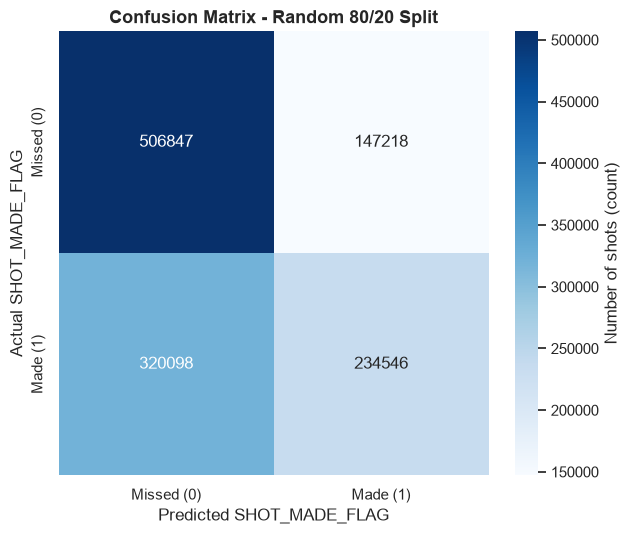

Saved -> reports/fig_confusion_matrix_random_split.png


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pivot_cm = confusion_random.pivot(index="label", columns="prediction", values="count").fillna(0)
axis_labels = ["Missed (0)", "Made (1)"]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(
    pivot_cm,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=axis_labels,
    yticklabels=axis_labels,
    cbar_kws={"label": "Number of shots (count)"},
    ax=ax,
)
ax.set_title("Confusion Matrix - Random 80/20 Split", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted SHOT_MADE_FLAG")
ax.set_ylabel("Actual SHOT_MADE_FLAG")
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_confusion_matrix_random_split.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_confusion_matrix_random_split.png")

**Interpretasi:** model jauh lebih baik mendeteksi shot yang MELESET (506,847 benar dari 654,065
aktual missed, ~77%) dibanding shot yang MASUK (234,546 benar dari 554,644 aktual made, hanya
~42%, sesuai recall 0.4229 di bagian 3.1). Kesalahan terbesar adalah 320,098 shot yang sebenarnya
MASUK tapi diprediksi MELESET (false negative) - jauh lebih banyak dari 147,218 kasus sebaliknya
(false positive). Ini mengindikasikan model baseline ini bias ke arah memprediksi "meleset", sejalan
dengan sifat fitur yang dipakai (jarak/zona) yang memang lebih kuat membedakan tembakan yang SANGAT
sulit (misal backcourt) daripada membedakan tembakan dengan tingkat kesulitan sedang yang sering
masuk atau meleset secara acak.

### 5.2 Feature importance (top 15 Logistic Regression coefficients)

**Apa yang divisualisasikan:** 15 fitur dengan koefisien absolut terbesar dari model Logistic
Regression (split random), satu bar per fitur (kategori one-hot ditulis sebagai `kolom=kategori`).

**Kenapa dibuat:** untuk menjawab pertanyaan "fitur mana yang paling menentukan apakah sebuah shot
masuk atau meleset?" secara visual - melengkapi tabel numerik di bagian 4, dan jadi acuan utama
untuk bagian interpretasi/limitasi di laporan.

**Sumber data:** `feature_importance` (bagian 4), label fitur dari `StringIndexer.labels` tiap
kolom kategorikal + nama kolom numerik, nilai dari `lr_model.coefficients`. Warna bar menandai arah
pengaruh: **biru = koefisien positif** (asosiasi dengan shot MASUK), **merah = koefisien negatif**
(asosiasi dengan shot MELESET) - oleh karena itu ditambahkan legend untuk menjelaskan 2 warna ini.

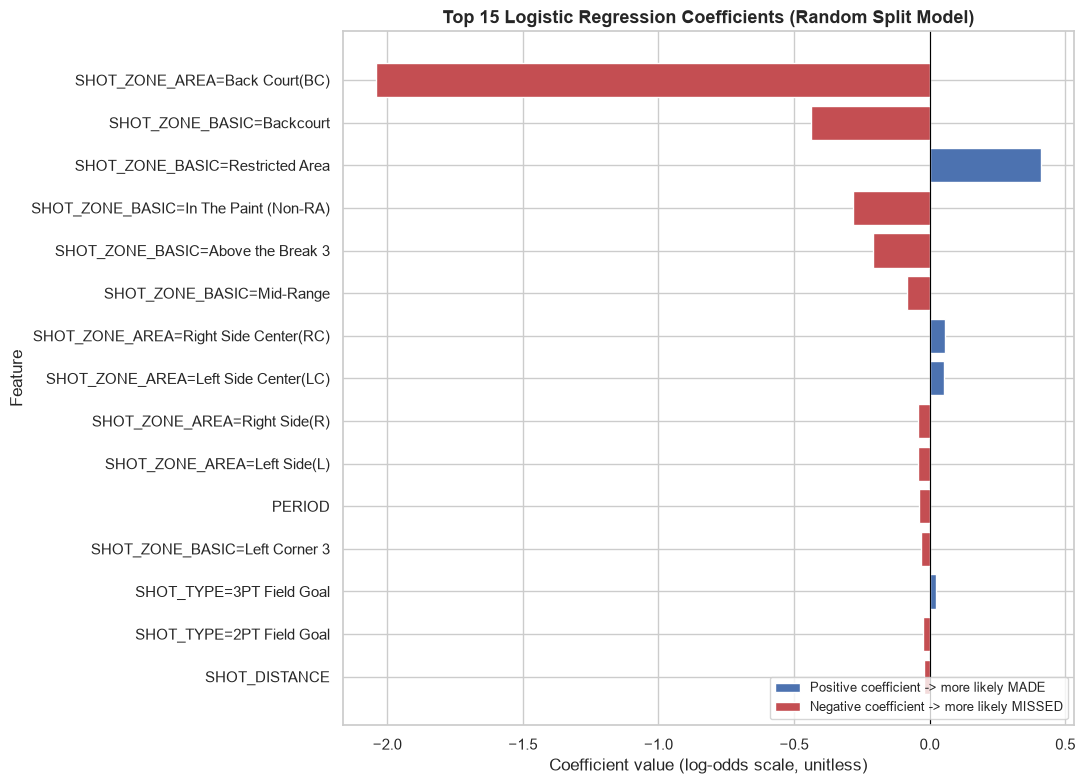

Saved -> reports/fig_feature_importance.png


In [17]:
from matplotlib.patches import Patch

top_features = feature_importance.head(15)

fig, ax = plt.subplots(figsize=(11, 8))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in top_features["coefficient"]]
ax.barh(top_features["feature"], top_features["coefficient"], color=colors)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Logistic Regression Coefficients (Random Split Model)", fontsize=13, fontweight="bold")
ax.set_xlabel("Coefficient value (log-odds scale, unitless)")
ax.set_ylabel("Feature")
legend_handles = [
    Patch(facecolor="#4C72B0", label="Positive coefficient -> more likely MADE"),
    Patch(facecolor="#C44E52", label="Negative coefficient -> more likely MISSED"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(REPORTS_DIR, "fig_feature_importance.png"), dpi=150)
plt.show()
print("Saved -> reports/fig_feature_importance.png")

**Interpretasi:** `SHOT_ZONE_AREA=Back Court(BC)` adalah fitur paling dominan secara signifikan
(koefisien -2.04, lebih dari 4x fitur terbesar kedua) - tembakan dari backcourt (heave/buzzer-beater)
hampir pasti meleset, sesuai intuisi basket. Setelah itu, `SHOT_ZONE_BASIC=Restricted Area` (+0.41)
dan `SHOT_ZONE_BASIC=Backcourt` (-0.44) menegaskan pola yang sama dari sisi *zona* tembakan: makin
dekat ring, makin mungkin masuk. Fitur numerik mentah (`SHOT_DISTANCE`, `SEASON`, `SCOREMARGIN`,
`time_remaining_seconds`) semuanya punya koefisien sangat kecil (<0.03) dibanding fitur zona -
menunjukkan bahwa *kategori zona tembakan* sudah menangkap hampir semua sinyal jarak yang relevan,
sehingga `SHOT_DISTANCE` mentah jadi relatif redundan setelah `SHOT_ZONE_BASIC`/`SHOT_ZONE_AREA`
dimasukkan ke model.

In [18]:
spark.stop()